In [1]:
# desactivar copilot @id:chat.disableAIFeatures
from astropy import constants as c
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
def IMF_kroupa(m):
    if m >= 0.01 and m < 0.08:
        alpha = 0.3
        c=1
    elif m >= 0.08 and m < 0.50:
        alpha = 1.3
        c=1
    elif m >= 0.50 and m < 1:
        alpha = 2.3
        c=0.5
    elif m >= 1:
        c=0.5
        alpha = 2.3

    xi = c*m**(-alpha) 

    return xi

In [3]:
# Masas entre 0.08 y 15 masas solares
masas_kroupa = np.arange (0.08, 15, 0.01)

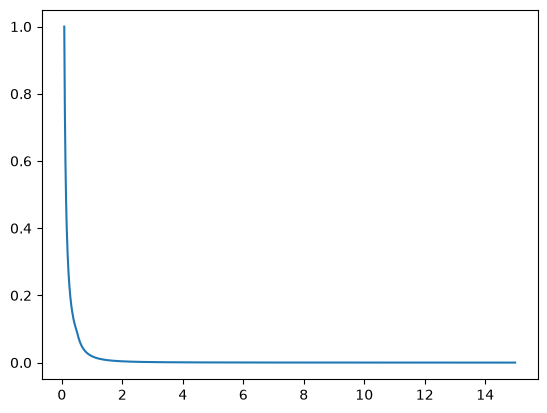

In [4]:
plt.plot(masas_kroupa, [IMF_kroupa(i)/IMF_kroupa(0.08) for i in masas_kroupa])

## El muestreo por rechazo es más intuitivo pero mucho menos eficiente que la transformada inversa, falta ver como funciona la transformada inversa.


In [5]:
# Muestreo por rechazo

#Tomo un valor de masa aleatoria entre el rango de masa
#Cálculo un número aleatorio entre 0 y 1
#Cálculo la IMF normalizada para la masa aleatoria
#Reviso si la likeliness/probabilidad de la masa es mayor o igual al número aleatorio
#Guardo la masa si la probabilidad (según Kroupa) de la masa es mayor que el número uniforme
# Ver si la masa aleatoria cae bajo la distribución de Kroupa
i = 0
masa = []
while i < 100000:
    # Masa propuesta, uniforme, osea de igual probabilidad que cualquier otra
    masa_preliminar = random.uniform(0.08, 15)
    aleatorio = random.uniform(0,1)

    # Normalización del valor en la IMF_kroupa, para que aparezca entre 0 y 1
    #igual que como aparece en el gráfico anterior.
    probability = IMF_kroupa(masa_preliminar)/IMF_kroupa(0.08)
    if probability >= aleatorio:
        masa.append(masa_preliminar)
        i +=1



In [6]:
#Que el star formation rate sea constante significa que se forman estrellas a la misma tasa a través del tiempo
# Ahora tenemos que evolucionarlas
# Además que tengamos el mismo star formation rate, significa que cualquiera de las masas que ya simulamos se pueden
# crear en casi todos los tiempos de la galaxia

# Por esto mismo deberíamos ahora encontrar un star formation rate en función del tiempo debido a los distintos procesos
# Age metallicity relation, pensando en las supernovas. 
# IMF, ya hecho
# SFR, que dijimos 
# Age-z, o sea la metalicidad con respecto del coso. 

In [7]:
weights = np.ones_like(masa) / len(masa)

In [14]:
len(masas_kroupa)

1492

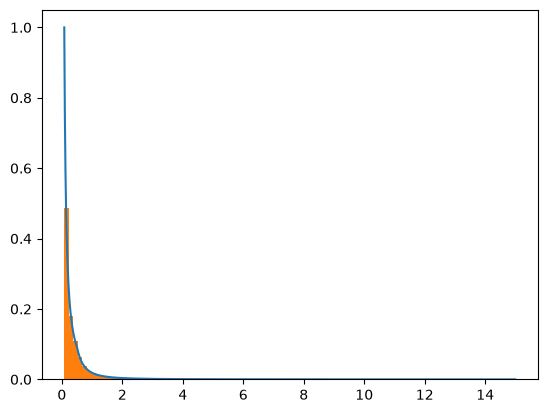

In [15]:
plt.plot(masas_kroupa, [IMF_kroupa(i)/IMF_kroupa(0.08) for i in masas_kroupa])
plt.hist(masa, bins=100, weights=weights)
plt.show()

In [16]:
# Generamos una edad aleatoria
born = []
edad = []
edad_MW = 136000
while len(born)<100000: # 10 Gyr
    edad_aleatoria = np.random.uniform(0,1000)
    born.append(edad_aleatoria)
    edad.append(edad_MW-edad_aleatoria)
    

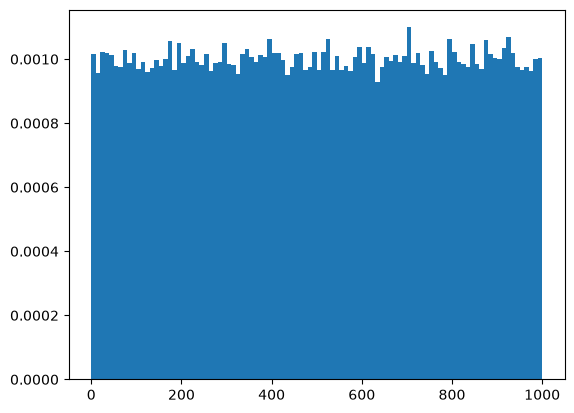

In [17]:
plt.hist(born,bins=100, density=True)
plt.show()

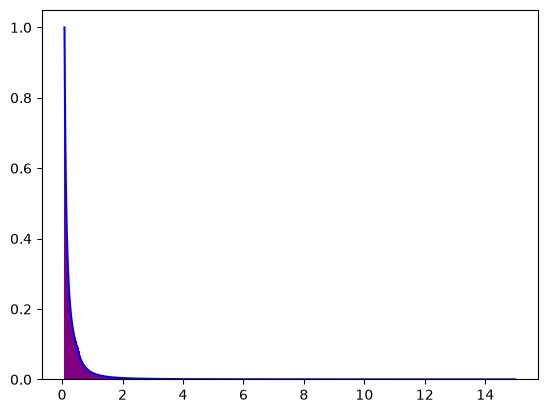

In [19]:
# Este deja más bonito el gráfico

counts, bins = np.histogram(masa, bins=1000)
counts_norm = counts/np.max(counts)
plt.bar(bins[:-1], counts_norm, width=np.diff(bins), color='purple')
plt.plot(masas_kroupa, [IMF_kroupa(i)/IMF_kroupa(0.08) for i in masas_kroupa], color='blue')
plt.show()

In [ ]:
# Tiempo en Main Sequence
t_MS = 10**10 * (masa)**(-2.5) # año

flag = []
i2 = 0
while i2 < len(t_MS):
    if t_MS > edad:
        i2 += 1
        flag.append("MS")
    if t_MS < edad:
        i2 += 1
        flag.append("Remanente")

In [ ]:
# Notita, cuando haga las metalicidades, tengo que interpolarlas.
# Peaks de enriquecimiento de metalicidad
# 12Gyr ago, z=-0.5
# 11Gyr ago, z = algo
# 10Gyr ago, z = algo
# Lo que coincide con los star formation rate